# Bài tập 3 — Instance segmentation trên TACO-10

**Mục tiêu:** suy luận với YOLO26-seg pretrained, chuẩn hóa TACO từ 60 lớp về 10 lớp COCO, fine-tune YOLO26n và YOLO26s, đánh giá mask AP và phân tích ảnh dự đoán. Phần mở rộng kiểm tra ảnh hưởng của lượng dữ liệu huấn luyện; ONNX FP32 được đánh giá như một phương án triển khai CPU.

Hai mô hình dùng cùng train/validation/test split và cấu hình huấn luyện. Mọi lựa chọn thí nghiệm dùng validation; test được chạy ở phần cuối.

In [1]:
import csv, json, random, time, platform
from collections import Counter, defaultdict
from copy import deepcopy
from pathlib import Path
from urllib.request import urlopen

import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd
import torch, yaml, onnx, onnxruntime as ort
from IPython.display import display, Image
from ultralytics import YOLO, settings
import ultralytics
from ultralytics.data.converter import merge_multi_segment

SEED = 42
IMG_SIZE = 640
EPOCHS = 200
PATIENCE = 20
TRAIN_BATCH = 8
WORKERS = 0
TRAIN_MODELS = True                # False: chỉ dùng best.pt đã có
EXPORT_ONNX = True
RUN_DATA_STUDY = True
RUN_FINAL_TEST = True             # Chỉ chuyển True SAU KHI đã chốt models/config trên VAL
BENCHMARK_IMAGES = 50
BENCHMARK_WARMUP = 10
BENCHMARK_REPEATS = 5

DATASET_ROOT = Path('/root/.cache/kagglehub/datasets/kneroma/tacotrashdataset/versions/3')
DATA_JSON = DATASET_ROOT / 'data/annotations.json'
IMAGE_ROOT = DATA_JSON.parent
ROOT = Path('/workspace/workspace/lt/taco10_study')
YOLO_ROOT = ROOT / 'yolo'
RUNS_ROOT = ROOT / 'runs'
EXPORT_ROOT = ROOT / 'exports'
REPORT_ROOT = ROOT / 'reports'
MODEL_SPECS = {'YOLO26n': 'yolo26n-seg.pt', 'YOLO26s': 'yolo26s-seg.pt'}
EXISTING_RUNS = {'YOLO26n': None, 'YOLO26s': None}  # Điền đường dẫn run khi TRAIN_MODELS=False
CLASSES = ['Bottle', 'Bottle cap', 'Can', 'Cigarette', 'Cup', 'Lid',
           'Plastic bag + wrapper', 'Pop tab', 'Straw', 'Other']

for folder in (ROOT, YOLO_ROOT, RUNS_ROOT, EXPORT_ROOT, REPORT_ROOT):
    folder.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert DATA_JSON.is_file(), f'Không thấy annotations: {DATA_JSON}. Kiểm tra đường dẫn dataset local.'
assert torch.cuda.is_available(), 'Máy local cần có CUDA để train.'
DEVICE = 0
print('GPU:', torch.cuda.get_device_name(0))
print('Torch:', torch.__version__, '| Ultralytics:', __import__('ultralytics').__version__)
settings.update({'tensorboard': True})
print('ONNX Runtime:', ort.__version__, '| Working dir:', ROOT)

COCO_ROOT = ROOT / 'coco'
COCO_ROOT.mkdir(exist_ok=True)
PRETRAINED_IMAGE = Path(ultralytics.__file__).parent / 'assets/bus.jpg'
assert PRETRAINED_IMAGE.is_file(), f'Không thấy ảnh demo: {PRETRAINED_IMAGE}'
run_dirs, checkpoints, train_seconds = {}, {}, {}
EXISTING_STUDY_RUNS = {25: None, 50: None}


GPU: NVIDIA GeForce RTX 5090
Torch: 2.7.0+cu128 | Ultralytics: 8.4.194
ONNX Runtime: 1.31.1 | Working dir: /workspace/workspace/lt/taco10_study


## 1. Inference với mô hình pretrained

Ảnh bus.jpg có người và xe buýt thuộc các lớp COCO. Cùng một ảnh được đưa qua YOLO26n-seg và YOLO26s-seg trước khi fine-tune; đây là demo suy luận, không phải điểm đánh giá trên TACO.

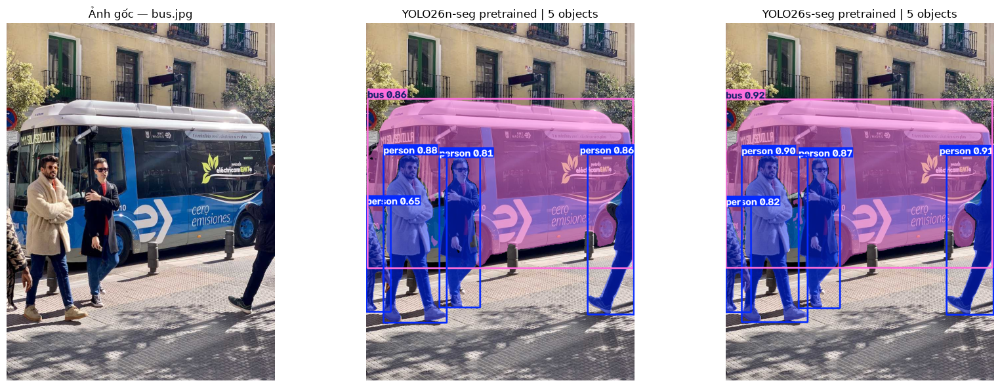

In [2]:
demo_bgr = cv2.imread(str(PRETRAINED_IMAGE))
demo_rgb = cv2.cvtColor(demo_bgr, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
axes[0].imshow(demo_rgb); axes[0].set_title('Ảnh gốc — bus.jpg')
for ax, (name, weight) in zip(axes[1:], MODEL_SPECS.items()):
    pred = YOLO(weight).predict(str(PRETRAINED_IMAGE), imgsz=IMG_SIZE, device=DEVICE,
                                conf=.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{name}-seg pretrained | {len(pred.boxes)} objects')
for ax in axes: ax.axis('off')
fig.tight_layout(); fig.savefig(REPORT_ROOT / 'pretrained_bus_n_s.png', dpi=150); plt.show()


## 2. Dữ liệu TACO và EDA

TACO gốc đã có annotation COCO. Ta gộp 60 nhãn thành 10 nhóm để bài toán vừa sức với tập 1.500 ảnh, sau đó quan sát độ lệch giữa các lớp và số vật thể trên mỗi ảnh.

In [3]:
raw = json.loads(DATA_JSON.read_text())
assert all(k in raw for k in ('images', 'annotations', 'categories'))
MAP_URL = 'https://raw.githubusercontent.com/pedropro/TACO/master/detector/taco_config/map_10.csv'
LOCAL_MAP = ROOT.parent / 'datasets/TACO/detector/taco_config/map_10.csv'
MAP_CACHE = LOCAL_MAP if LOCAL_MAP.is_file() else ROOT / 'map_10.csv'
if not MAP_CACHE.exists():
    with urlopen(MAP_URL, timeout=30) as response:
        MAP_CACHE.write_bytes(response.read())
with MAP_CACHE.open(newline='') as f:
    mapping = dict(csv.reader(f))
original_names = {c['id']: c['name'] for c in raw['categories']}
missing = [name for name in original_names.values() if name not in mapping]
assert not missing, f'Unmapped original classes: {missing}'
unknown = sorted(set(mapping[name] for name in original_names.values()) - set(CLASSES))
assert not unknown, f'Unexpected target classes: {unknown}'
id_to_target = {cid: CLASSES.index(mapping[name]) for cid, name in original_names.items()}
taco10 = deepcopy(raw)
taco10['categories'] = [{'id': i+1, 'name': name, 'supercategory': 'litter'}
                        for i, name in enumerate(CLASSES)]
for ann in taco10['annotations']:
    ann['category_id'] = id_to_target[ann['category_id']] + 1
counts = Counter(a['category_id'] for a in taco10['annotations'])
class_table = pd.DataFrame({'Class': CLASSES, 'Instances': [counts[i+1] for i in range(10)]})
display(class_table)
print(f"Images: {len(taco10['images'])}, annotations: {len(taco10['annotations'])}, classes: {len(CLASSES)}")


,Class,Instances
0,Bottle,439
1,Bottle cap,289
2,Can,273
3,Cigarette,667
4,Cup,192
5,Lid,87
6,Plastic bag + wrapper,850
7,Pop tab,99
8,Straw,161
9,Other,1727


Images: 1500, annotations: 4784, classes: 10


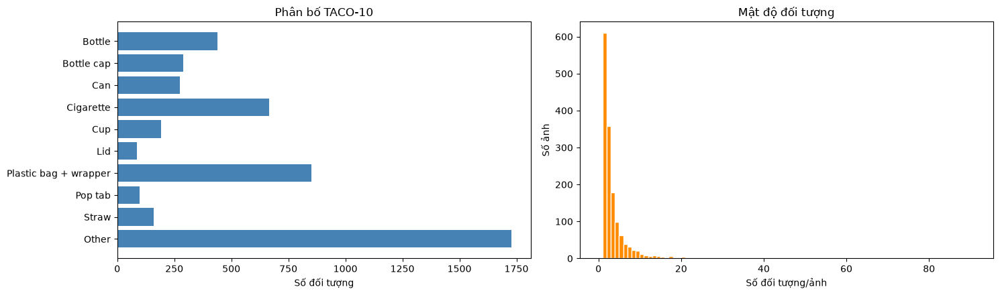

In [4]:
objects_per_image = Counter(a['image_id'] for a in taco10['annotations'])
image_counts = [objects_per_image[im['id']] for im in taco10['images']]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(CLASSES, [counts[i + 1] for i in range(len(CLASSES))], color='steelblue')
axes[0].invert_yaxis(); axes[0].set(xlabel='Số đối tượng', title='Phân bố TACO-10')
axes[1].hist(image_counts, bins=range(max(image_counts) + 2), color='darkorange', edgecolor='white')
axes[1].set(xlabel='Số đối tượng/ảnh', ylabel='Số ảnh', title='Mật độ đối tượng')
fig.tight_layout(); fig.savefig(REPORT_ROOT / 'eda_taco10.png', dpi=150); plt.show()


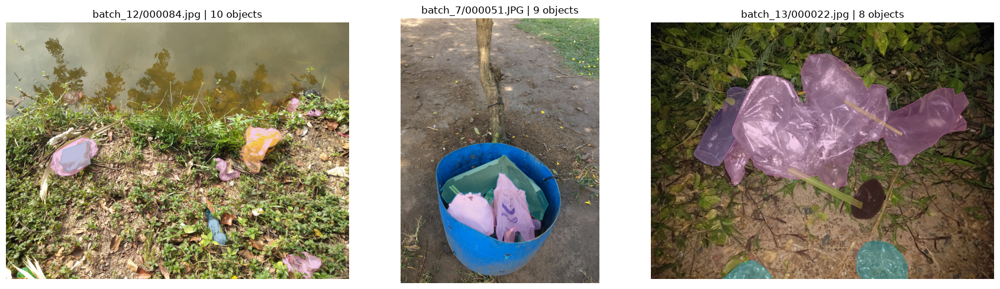

In [5]:
from matplotlib.patches import Polygon

by_image = defaultdict(list)
for ann in taco10['annotations']: by_image[ann['image_id']].append(ann)
candidates = sorted(
    (info for info in taco10['images']
     if 3 <= len(by_image[info['id']]) <= 10
     and len({a['category_id'] for a in by_image[info['id']]}) >= 2
     and .03 < sum(a.get('area', 0) for a in by_image[info['id']]) /
     (info['width'] * info['height']) < .4),
    key=lambda info: (len({a['category_id'] for a in by_image[info['id']]}),
                      len(by_image[info['id']])),
    reverse=True
)
samples, used_batches = [], set()
for info in candidates:
    batch = Path(info['file_name']).parts[0]
    if batch not in used_batches:
        samples.append(info); used_batches.add(batch)
    if len(samples) == 3: break
assert len(samples) == 3
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, info in zip(axes, samples):
    image = cv2.imread(str(IMAGE_ROOT / info['file_name']))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    for ann in by_image[info['id']]:
        seg = ann.get('segmentation', [])
        if not isinstance(seg, list): continue
        color = plt.get_cmap('tab10')((ann['category_id'] - 1) % 10)
        for poly in seg:
            if len(poly) >= 6:
                ax.add_patch(Polygon(np.asarray(poly).reshape(-1, 2), closed=True,
                                     facecolor=color, edgecolor=color, alpha=.35))
    ax.set_title(f'{info["file_name"]} | {len(by_image[info["id"]])} objects')
    ax.axis('off')
fig.tight_layout(); fig.savefig(REPORT_ROOT / 'eda_gt_examples.png', dpi=150); plt.show()


Nhận xét EDA: phân bố lớp không đều (Other có 1.727 đối tượng, Lid chỉ có 87). Vì vậy điểm mAP tổng thể cần được đọc cùng AP từng lớp và các ví dụ sai ở phần đánh giá.

## 3. COCO TACO-10, split cố định và nhãn YOLO

Ánh xạ lớp được áp dụng vào COCO JSON. Split 1.200/150/150 được lưu bằng image ID để mọi mô hình và phần mở rộng dùng cùng tập validation/test. Nhãn polygon được đổi sang định dạng YOLO-seg.

In [6]:
SPLIT_FILE = ROOT / 'split_ids.json'
all_ids = [int(im['id']) for im in taco10['images']]
assert len(all_ids) == len(set(all_ids)), 'Trùng image ID'
assert len(all_ids) > 1350, f'Dataset có {len(all_ids)} ảnh, không đủ split dự kiến'
if SPLIT_FILE.exists():
    split_lists = json.loads(SPLIT_FILE.read_text())
    assert set(map(int, sum(split_lists.values(), []))) == set(all_ids), 'Manifest không khớp dataset'
else:
    ids = np.random.default_rng(SEED).permutation(all_ids).tolist()
    split_lists = {'train': ids[:1200], 'val': ids[1200:1350], 'test': ids[1350:]}
    SPLIT_FILE.write_text(json.dumps(split_lists, indent=2))
splits = {key: set(map(int, value)) for key, value in split_lists.items()}
assert not (splits['train'] & splits['val'] or splits['val'] & splits['test'] or splits['train'] & splits['test'])
subset_jsons = {}
rows = []
for split, ids in splits.items():
    subset = {'info': taco10.get('info', {}), 'licenses': taco10.get('licenses', []),
              'images': [im for im in taco10['images'] if im['id'] in ids],
              'annotations': [a for a in taco10['annotations'] if a['image_id'] in ids],
              'categories': taco10['categories']}
    path = COCO_ROOT / f'{split}.json'
    path.write_text(json.dumps(subset))
    subset_jsons[split] = path
    c = Counter(a['category_id'] for a in subset['annotations'])
    for k, cls in enumerate(CLASSES, 1):
        rows.append({'Split': split, 'Class': cls, 'Instances': c[k]})
    print(f'{split}: {len(subset["images"])} images, {len(subset["annotations"])} instances')
distribution = pd.DataFrame(rows).pivot(index='Class', columns='Split', values='Instances')[['train','val','test']]
display(distribution)
if (distribution == 0).any().any():
    print('WARNING: có lớp vắng mặt ở một split; per-class AP có thể không xác định.')


train: 1200 images, 3755 instances
val: 150 images, 526 instances
test: 150 images, 503 instances


Split,train,val,test
Class,,,
Bottle,352,45,42
Bottle cap,228,29,32
Can,224,17,32
Cigarette,507,97,63
Cup,152,24,16
Lid,62,19,6
Other,1359,164,204
Plastic bag + wrapper,654,110,86
Pop tab,78,7,14


In [7]:
missing_images = [im['file_name'] for im in taco10['images'] if not (IMAGE_ROOT / im['file_name']).is_file()]
assert not missing_images, f'Thiếu {len(missing_images)} ảnh trong {IMAGE_ROOT}; ví dụ: {missing_images[:5]}'
print('Image root:', IMAGE_ROOT)

converted_counts = {}
for split, json_path in subset_jsons.items():
    subset = json.loads(json_path.read_text())
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    by_image = defaultdict(list)
    for a in subset['annotations']:
        by_image[a['image_id']].append(a)
    kept, skipped = 0, 0
    for info in subset['images']:
        src = IMAGE_ROOT / info['file_name']
        assert src.is_file(), f'Ảnh thiếu: {src}'
        dst = image_dir / f"{info['id']}{src.suffix.lower()}"
        if not dst.exists():
            dst.symlink_to(src)
        lines = []
        for ann in by_image[info['id']]:
            seg = ann.get('segmentation', [])
            if isinstance(seg, dict):
                raise ValueError(f"RLE segmentation unsupported; annotation id={ann.get('id')}")
            if not isinstance(seg, list):
                skipped += 1
                continue
            polygons = [np.asarray(poly, dtype=np.float32).reshape(-1, 2)
                        for poly in seg if isinstance(poly, list) and len(poly) >= 6 and len(poly)%2 == 0]
            if not polygons:
                skipped += 1
                continue
            try:
                pts = (np.concatenate(merge_multi_segment(polygons), axis=0)
                       if len(polygons) > 1 else polygons[0].copy())
            except Exception as exc:
                raise RuntimeError(f"Bad polygon annotation id={ann.get('id')}") from exc
            if len(pts) < 3 or not np.isfinite(pts).all():
                skipped += 1
                continue
            pts[:, 0] = np.clip(pts[:, 0] / info['width'], 0, 1)
            pts[:, 1] = np.clip(pts[:, 1] / info['height'], 0, 1)
            if np.unique(pts, axis=0).shape[0] < 3:
                skipped += 1
                continue
            lines.append(f"{ann['category_id'] - 1} " + ' '.join(f'{v:.6f}' for v in pts.ravel()))
            kept += 1
        (label_dir / f"{info['id']}.txt").write_text('\n'.join(lines))
    converted_counts[split] = {'kept': kept, 'skipped': skipped}
    print(f'{split}: kept={kept}, skipped={skipped}, images={len(subset["images"])}')

yaml_path = YOLO_ROOT / 'data.yaml'
yaml_path.write_text(yaml.safe_dump({'path': str(YOLO_ROOT), 'train': 'images/train',
                                     'val': 'images/val', 'test': 'images/test',
                                     'names': dict(enumerate(CLASSES))}, sort_keys=False))
assert all(len(list((YOLO_ROOT/'images'/s).iterdir())) == len(splits[s]) for s in splits)
(ROOT / 'conversion_stats.json').write_text(json.dumps(converted_counts, indent=2))
print('Dataset YAML:', yaml_path)


Image root: /root/.cache/kagglehub/datasets/kneroma/tacotrashdataset/versions/3/data


train: kept=3755, skipped=0, images=1200
val: kept=526, skipped=0, images=150
test: kept=503, skipped=0, images=150
Dataset YAML: /workspace/workspace/lt/taco10_study/yolo/data.yaml


In [8]:
assert sum(len(ids) for ids in splits.values()) == len(taco10['images'])
assert all((IMAGE_ROOT / im['file_name']).is_file() for im in taco10['images'])
assert all((YOLO_ROOT / 'images' / s).exists() for s in splits)
print('COCO TACO-10:', {s: str(p) for s, p in subset_jsons.items()})
print('YOLO dataset:', yaml_path)
print('Polygon conversion:', converted_counts)


COCO TACO-10: {'train': '/workspace/workspace/lt/taco10_study/coco/train.json', 'val': '/workspace/workspace/lt/taco10_study/coco/val.json', 'test': '/workspace/workspace/lt/taco10_study/coco/test.json'}
YOLO dataset: /workspace/workspace/lt/taco10_study/yolo/data.yaml
Polygon conversion: {'train': {'kept': 3755, 'skipped': 0}, 'val': {'kept': 526, 'skipped': 0}, 'test': {'kept': 503, 'skipped': 0}}


## 4. Fine-tune YOLO26n và YOLO26s

Cả hai lần train dùng cùng split, seed, kích thước ảnh, batch, số epoch tối đa và early stopping. Mỗi mô hình có cell riêng và lưu checkpoint tốt nhất theo validation. Ultralytics ghi results.csv, hình huấn luyện và TensorBoard trong thư mục run.

In [9]:
name = 'YOLO26n'
if TRAIN_MODELS:
    model_n = YOLO(MODEL_SPECS[name])
    start = time.perf_counter()
    model_n.train(data=str(yaml_path), epochs=EPOCHS, patience=PATIENCE,
                  imgsz=IMG_SIZE, batch=TRAIN_BATCH, device=DEVICE, workers=WORKERS,
                  seed=SEED, deterministic=True, project=str(RUNS_ROOT),
                  name='yolo26n_taco10', exist_ok=False, plots=True, save=True, save_period=20)
    run_n = Path(model_n.trainer.save_dir)
    train_seconds[name] = time.perf_counter() - start
    (run_n / 'study_metadata.json').write_text(json.dumps({'train_seconds': train_seconds[name], 'train_percent': 100}))
    del model_n
    torch.cuda.empty_cache()
else:
    assert EXISTING_RUNS[name], f'Điền EXISTING_RUNS[{name!r}]'
    run_n = Path(EXISTING_RUNS[name])
    info = run_n / 'study_metadata.json'
    train_seconds[name] = json.loads(info.read_text())['train_seconds'] if info.exists() else float('nan')
run_dirs[name], checkpoints[name] = run_n, run_n / 'weights/best.pt'
assert checkpoints[name].is_file() and (run_n / 'results.csv').is_file()
print(name, '=>', checkpoints[name])


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/workspace/lt/taco10_study/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_taco10-8, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, persp

TensorBoard: Start with 'tensorboard --logdir /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10-8', view at http://localhost:6006/


Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


...

                 Straw         12         14     0.0966      0.123     0.0473     0.0325      0.163      0.214      0.145     0.0395


                 Other         74        164      0.366      0.274      0.227      0.164      0.346       0.28      0.223      0.161


Speed: 0.1ms preprocess, 1.6ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10-8


YOLO26n => /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10-8/weights/best.pt


In [10]:
name = 'YOLO26s'
if TRAIN_MODELS:
    model_s = YOLO(MODEL_SPECS[name])
    start = time.perf_counter()
    model_s.train(data=str(yaml_path), epochs=EPOCHS, patience=PATIENCE,
                  imgsz=IMG_SIZE, batch=TRAIN_BATCH, device=DEVICE, workers=WORKERS,
                  seed=SEED, deterministic=True, project=str(RUNS_ROOT),
                  name='yolo26s_taco10', exist_ok=False, plots=True, save=True, save_period=20)
    run_s = Path(model_s.trainer.save_dir)
    train_seconds[name] = time.perf_counter() - start
    (run_s / 'study_metadata.json').write_text(json.dumps({'train_seconds': train_seconds[name], 'train_percent': 100}))
    del model_s
    torch.cuda.empty_cache()
else:
    assert EXISTING_RUNS[name], f'Điền EXISTING_RUNS[{name!r}]'
    run_s = Path(EXISTING_RUNS[name])
    info = run_s / 'study_metadata.json'
    train_seconds[name] = json.loads(info.read_text())['train_seconds'] if info.exists() else float('nan')
run_dirs[name], checkpoints[name] = run_s, run_s / 'weights/best.pt'
assert checkpoints[name].is_file() and (run_s / 'results.csv').is_file()
print(name, '=>', checkpoints[name])


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/workspace/lt/taco10_study/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_taco10-7, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, persp

TensorBoard: Start with 'tensorboard --logdir /workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7', view at http://localhost:6006/


Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


...

                 Straw         12         14       0.13      0.214      0.143        0.1      0.169      0.214        0.2     0.0766


                 Other         74        164      0.192      0.348       0.19      0.135       0.21      0.341      0.186      0.122


Speed: 0.1ms preprocess, 2.0ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7


YOLO26s => /workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7/weights/best.pt


### Loss, Mask mAP và TensorBoard

Biểu đồ bên dưới đọc trực tiếp results.csv từ hai run. TensorBoard đã được bật trong cell cấu hình; mở thư mục runs bằng lệnh tensorboard --logdir <đường dẫn RUNS_ROOT> trong terminal để xem log theo epoch.

YOLO26n completed epochs: 48
YOLO26s completed epochs: 34


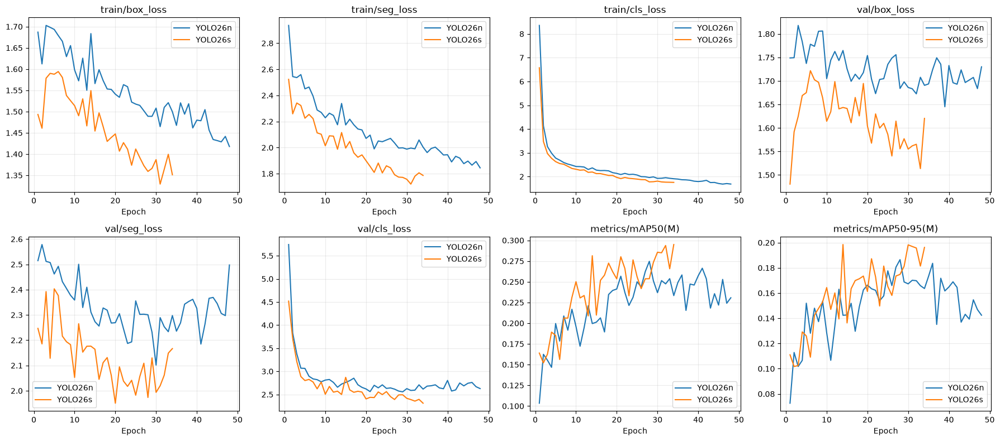

In [11]:
metrics = ['train/box_loss', 'train/seg_loss', 'train/cls_loss',
           'val/box_loss', 'val/seg_loss', 'val/cls_loss',
           'metrics/mAP50(M)', 'metrics/mAP50-95(M)']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for name, run_dir in run_dirs.items():
    h = pd.read_csv(run_dir / 'results.csv')
    h.columns = h.columns.str.strip()
    for ax, metric in zip(axes.flat, metrics):
        if metric in h.columns:
            ax.plot(h['epoch'], h[metric], label=name)
        ax.set(title=metric, xlabel='Epoch')
        ax.grid(alpha=.25)
    print(name, 'completed epochs:', len(h))
for ax in axes.flat:
    if ax.has_data(): ax.legend()
plt.tight_layout(); plt.savefig(REPORT_ROOT/'train_curves.png', dpi=160); plt.show()


In [12]:
event_files = {name: list(run.rglob('events.out.tfevents.*')) for name, run in run_dirs.items()}
for name, files in event_files.items(): print(name, '| TensorBoard events:', len(files), '| run:', run_dirs[name])
assert all(event_files.values()), 'Thiếu TensorBoard event file; kiểm tra TensorBoard setting trước khi train.'


YOLO26n | TensorBoard events: 1 | run: /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10-8
YOLO26s | TensorBoard events: 1 | run: /workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7


## 5. Đánh giá validation và phân tích lỗi

Mask mAP50-95 là chỉ số chính. AP theo lớp cho thấy các nhóm rác khó; ảnh minh họa được chọn bằng mask F1 theo ảnh thay vì lấy ngẫu nhiên. Tập test chưa dùng ở phần này.

In [13]:
def eval_seg(model_path, split='val', device='cpu'):
    m = YOLO(str(model_path), task='segment').val(
        data=str(yaml_path), split=split, imgsz=IMG_SIZE, batch=1,
        device=device, rect=False, plots=False, verbose=False)
    scores = {'Box mAP50': float(m.box.map50), 'Box mAP50-95': float(m.box.map),
              'Mask mAP50': float(m.seg.map50), 'Mask mAP50-95': float(m.seg.map)}
    byclass = {CLASSES[int(i)]: float(ap)
               for i, ap in zip(m.seg.ap_class_index, m.seg.ap)}
    return scores, byclass

val_rows, val_per_class = {}, {}
for name, path in checkpoints.items():
    val_rows[f'{name} PyTorch'], val_per_class[f'{name} PyTorch'] = eval_seg(path, 'val', DEVICE)
val_table = pd.DataFrame(val_rows).T
val_table.to_csv(REPORT_ROOT/'validation_pytorch.csv')
display(val_table.round(4))
display(pd.DataFrame(val_per_class).reindex(CLASSES).round(4))


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7925.1±1305.7 MB/s, size: 1727.9 KB)


                   all        150        526      0.455      0.287      0.273      0.198      0.462      0.278      0.258      0.169


Speed: 0.7ms preprocess, 7.0ms inference, 0.0ms loss, 1.6ms postprocess per image


...

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9424.1±1017.0 MB/s, size: 1055.3 KB)


                   all        150        526      0.387      0.304      0.294       0.22      0.384      0.292       0.28      0.194


Speed: 0.8ms preprocess, 7.7ms inference, 0.0ms loss, 1.6ms postprocess per image


,Box mAP50,Box mAP50-95,Mask mAP50,Mask mAP50-95
YOLO26n PyTorch,0.2730,0.1981,0.2582,0.1692
YOLO26s PyTorch,0.2941,0.2205,0.2799,0.1940


,YOLO26n PyTorch,YOLO26s PyTorch
Bottle,0.3824,0.3940
Bottle cap,0.1759,0.1182
Can,0.2450,0.4910
Cigarette,0.0191,0.0413
Cup,0.1394,0.2275
Lid,0.3997,0.3007
Plastic bag + wrapper,0.1456,0.1836
Pop tab,0.0015,0.0013
Straw,0.0376,0.0625
Other,0.1463,0.1202


In [14]:
from matplotlib.patches import Polygon

N_PER_GROUP = 4
CONF = 0.25
model_names = list(MODEL_SPECS)
models = {name: YOLO(str(checkpoints[name]), task='segment') for name in model_names}

# Xếp hạng bằng kết quả mask trên validation, cùng ngưỡng với ảnh minh họa.
per_image = {}
for name, model in models.items():
    metrics = model.val(
        data=str(yaml_path), split='val', imgsz=IMG_SIZE, batch=1,
        device=DEVICE, rect=False, conf=CONF, plots=False, verbose=False
    )
    per_image[name] = dict(metrics.seg.image_metrics)

image_paths = sorted(
    p for p in (YOLO_ROOT / 'images/val').iterdir()
    if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
)
rows = []
for path in image_paths:
    if any(path.name not in per_image[name] for name in model_names):
        continue
    label = YOLO_ROOT / 'labels/val' / f'{path.stem}.txt'
    gt_count = len(label.read_text().splitlines()) if label.exists() else 0
    row = {'path': path, 'image': path.name, 'GT': gt_count}
    for name in model_names:
        score = per_image[name][path.name]
        row.update({f'{name}_{key}': score[key] for key in ('f1', 'tp', 'fp', 'fn')})
    rows.append(row)

ranking = pd.DataFrame(rows)
assert not ranking.empty, 'Không tìm thấy kết quả theo ảnh'
f1_cols = [f'{name}_f1' for name in model_names]
fn_cols = [f'{name}_fn' for name in model_names]
ranking['min_F1'] = ranking[f1_cols].min(axis=1)
ranking['mean_F1'] = ranking[f1_cols].mean(axis=1)
ranking['mean_FN'] = ranking[fn_cols].mean(axis=1)

# Ưu tiên ảnh có ít nhất hai đối tượng để ví dụ trực quan hơn.
pool = ranking[ranking['GT'] >= 2]
if len(pool) < 2 * N_PER_GROUP:
    pool = ranking
best = pool.sort_values(['min_F1', 'GT'], ascending=[False, False]).head(N_PER_GROUP)
worst = pool.drop(best.index).sort_values(
    ['mean_F1', 'mean_FN'], ascending=[True, False]
).head(N_PER_GROUP)

ranking.drop(columns='path').to_csv(REPORT_ROOT / 'gallery_image_ranking.csv', index=False)
display(pd.concat([best.assign(Group='Best'), worst.assign(Group='Worst')])[
    ['Group', 'image', 'GT', *f1_cols, 'mean_F1']
].round(2))


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9600.4±1690.2 MB/s, size: 2151.3 KB)


                   all        150        526      0.434      0.264      0.192      0.148      0.434      0.259      0.185       0.13


Speed: 0.8ms preprocess, 7.0ms inference, 0.0ms loss, 1.3ms postprocess per image


...

YOLO26s-seg summary (fused): 136 layers, 10,369,210 parameters, 0 gradients, 34.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3032.2±1482.8 MB/s, size: 1152.5 KB)


                   all        150        526      0.385      0.302      0.225      0.177      0.375      0.291      0.219      0.159


Speed: 0.7ms preprocess, 7.1ms inference, 0.0ms loss, 1.3ms postprocess per image


,Group,image,GT,YOLO26n_f1,YOLO26s_f1,mean_F1
22,Best,1136.jpg,3,0.80,0.67,0.73
17,Best,1099.jpg,2,0.67,0.67,0.67
21,Best,1133.jpg,2,0.67,0.67,0.67
72,Best,247.jpg,2,1.00,0.67,0.83
80,Worst,348.jpg,11,0.00,0.00,0.00
9,Worst,1048.jpg,5,0.00,0.00,0.00
50,Worst,13.jpg,4,0.00,0.00,0.00
58,Worst,1439.jpg,4,0.00,0.00,0.00


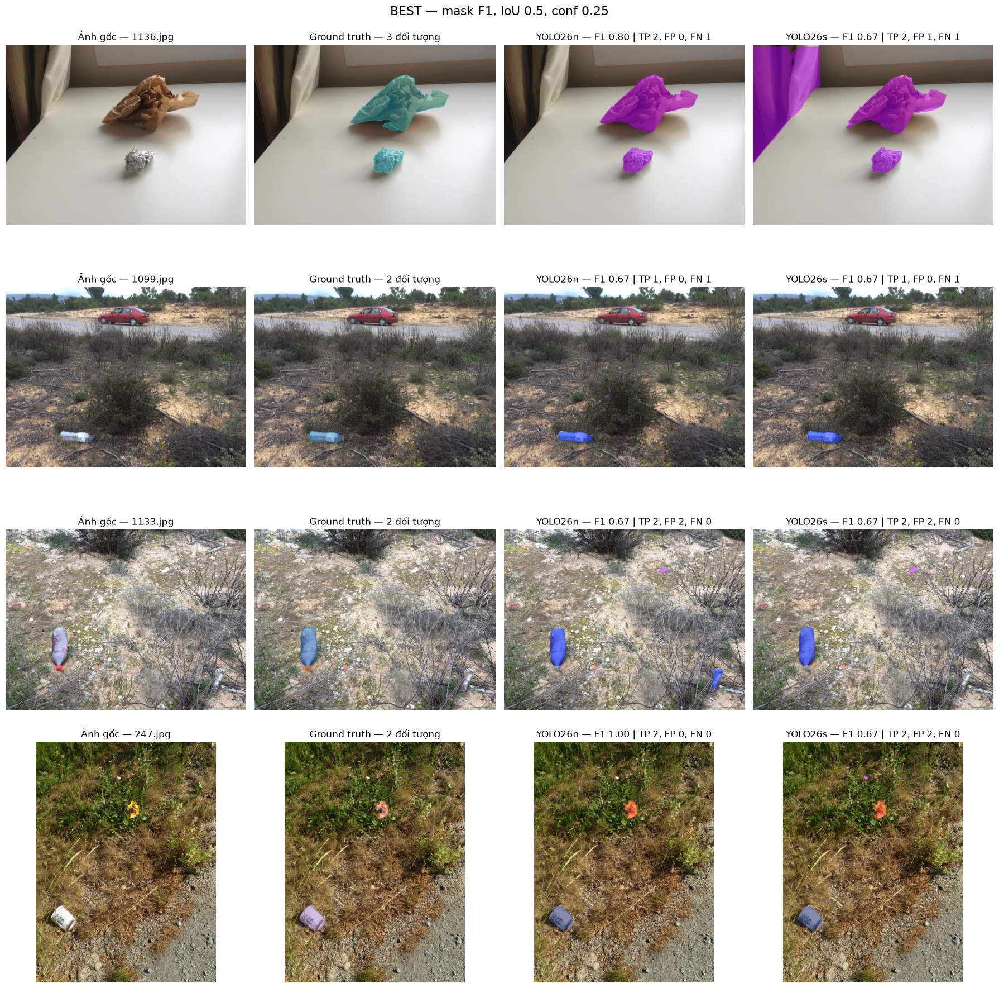

Đã lưu: /workspace/workspace/lt/taco10_study/reports/gallery_best_validation.png


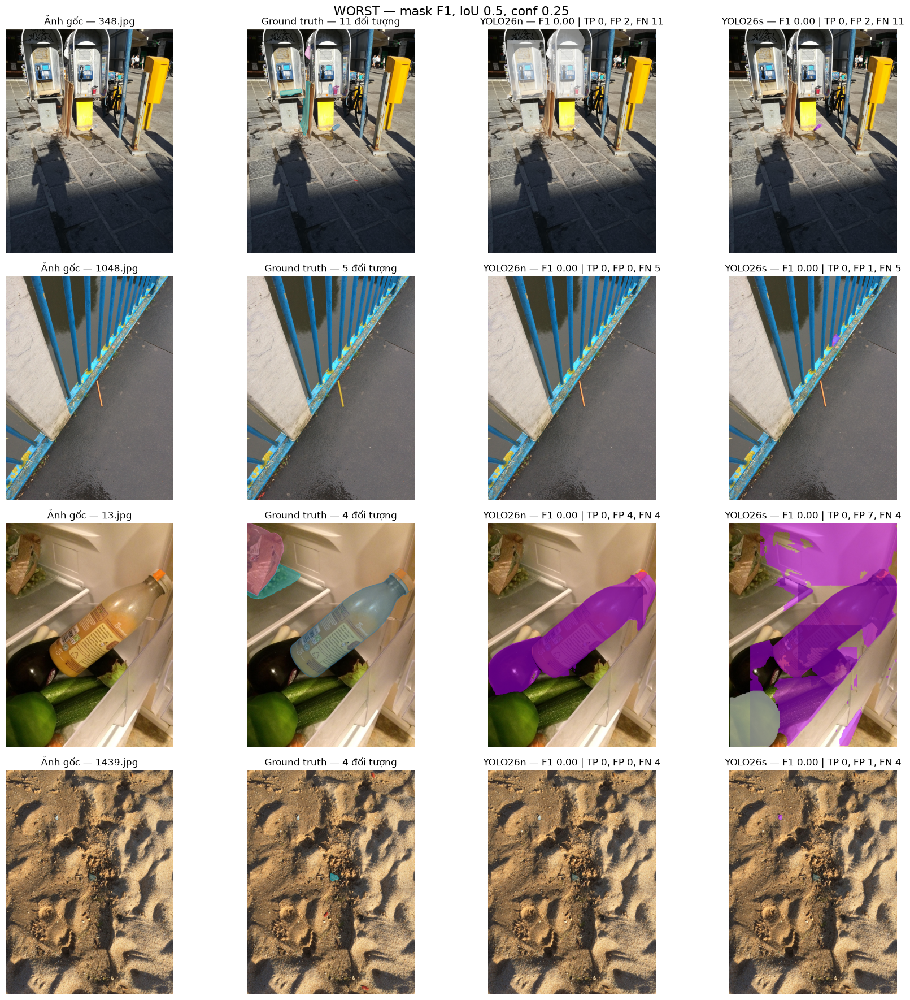

Đã lưu: /workspace/workspace/lt/taco10_study/reports/gallery_worst_validation.png


In [15]:
for group, selected in [('best', best), ('worst', worst)]:
    fig, axes = plt.subplots(len(selected), 4, figsize=(18, 4.5 * len(selected)),
                             squeeze=False)
    for row_idx, row in enumerate(selected.itertuples()):
        path = row.path
        bgr = cv2.imread(str(path))
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        height, width = rgb.shape[:2]

        axes[row_idx, 0].imshow(rgb)
        axes[row_idx, 0].set_title(f'Ảnh gốc — {path.name}')

        axes[row_idx, 1].imshow(rgb)
        label = YOLO_ROOT / 'labels/val' / f'{path.stem}.txt'
        for line in label.read_text().splitlines():
            values = np.fromstring(line, sep=' ')
            if len(values) < 7:
                continue
            points = values[1:].reshape(-1, 2) * [width, height]
            color = plt.get_cmap('tab10')(int(values[0]) % 10)
            axes[row_idx, 1].add_patch(
                Polygon(points, closed=True, facecolor=color,
                        edgecolor=color, linewidth=1, alpha=0.4)
            )
        axes[row_idx, 1].set_title(f'Ground truth — {row.GT} đối tượng')

        for col, name in enumerate(model_names, start=2):
            pred = models[name].predict(
                str(path), device=DEVICE, imgsz=IMG_SIZE,
                conf=CONF, rect=False, verbose=False
            )[0]
            shown = cv2.cvtColor(
                pred.plot(boxes=False, labels=False, conf=False),
                cv2.COLOR_BGR2RGB
            )
            axes[row_idx, col].imshow(shown)
            score = per_image[name][path.name]
            axes[row_idx, col].set_title(
                f'{name} — F1 {score["f1"]:.2f} | '
                f'TP {score["tp"]}, FP {score["fp"]}, FN {score["fn"]}'
            )

        for ax in axes[row_idx]:
            ax.axis('off')

    fig.suptitle(f'{group.upper()} — mask F1, IoU 0.5, conf {CONF}', fontsize=16)
    fig.tight_layout()
    output = REPORT_ROOT / f'gallery_{group}_validation.png'
    fig.savefig(output, dpi=150, bbox_inches='tight')
    plt.show()
    print('Đã lưu:', output)


## 6. Mở rộng: 25%, 50% và 100% dữ liệu train

Chỉ YOLO26n được dùng cho nghiên cứu lượng dữ liệu. Hai subset 25% và 50% là tập lồng nhau, chọn ngẫu nhiên cố định từ 1.200 ảnh train; 100% là run YOLO26n chính. Validation và test giữ nguyên.

In [16]:
train_files = sorted(p for p in (YOLO_ROOT / 'images/train').iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
assert len(train_files) == len(splits['train'])
order = np.random.default_rng(SEED + 1).permutation(len(train_files))
study_yaml = {}
for percent in (25, 50):
    selected = [train_files[i] for i in order[:len(train_files) * percent // 100]]
    image_dir = YOLO_ROOT / f'images/train_{percent}'
    label_dir = YOLO_ROOT / f'labels/train_{percent}'
    image_dir.mkdir(parents=True, exist_ok=True); label_dir.mkdir(parents=True, exist_ok=True)
    for src in selected:
        image_link = image_dir / src.name
        label_src = YOLO_ROOT / 'labels/train' / f'{src.stem}.txt'
        label_link = label_dir / label_src.name
        if not image_link.is_symlink(): image_link.symlink_to(src.resolve())
        if not label_link.is_symlink(): label_link.symlink_to(label_src.resolve())
    assert len(list(image_dir.iterdir())) == len(selected)
    study_yaml[percent] = ROOT / f'data_train_{percent}.yaml'
    study_yaml[percent].write_text(yaml.safe_dump({
        'path': str(YOLO_ROOT), 'train': f'images/train_{percent}',
        'val': 'images/val', 'test': 'images/test',
        'names': dict(enumerate(CLASSES))
    }, sort_keys=False))
    print(f'{percent}%: {len(selected)} train images | {study_yaml[percent]}')


25%: 300 train images | /workspace/workspace/lt/taco10_study/data_train_25.yaml
50%: 600 train images | /workspace/workspace/lt/taco10_study/data_train_50.yaml


In [17]:
percent = 25
if RUN_DATA_STUDY:
    model_25 = YOLO(MODEL_SPECS['YOLO26n'])
    start = time.perf_counter()
    model_25.train(data=str(study_yaml[percent]), epochs=EPOCHS, patience=PATIENCE,
                   imgsz=IMG_SIZE, batch=TRAIN_BATCH, device=DEVICE, workers=WORKERS,
                   seed=SEED, deterministic=True, project=str(RUNS_ROOT),
                   name='yolo26n_taco10_train25', exist_ok=False, plots=True, save=True)
    study_run_25 = Path(model_25.trainer.save_dir)
    study_time_25 = time.perf_counter() - start
    (study_run_25 / 'study_metadata.json').write_text(json.dumps({'train_seconds': study_time_25, 'train_percent': percent}))
    del model_25
    torch.cuda.empty_cache()
else:
    assert EXISTING_STUDY_RUNS[percent], 'Điền đường dẫn run 25%'
    study_run_25 = Path(EXISTING_STUDY_RUNS[percent])
    study_time_25 = json.loads((study_run_25 / 'study_metadata.json').read_text())['train_seconds']
study_ckpt_25 = study_run_25 / 'weights/best.pt'
assert study_ckpt_25.is_file()
print('25% =>', study_ckpt_25)


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/workspace/lt/taco10_study/data_train_25.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_taco10_train25-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

TensorBoard: Start with 'tensorboard --logdir /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train25-3', view at http://localhost:6006/


Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


...

                 Straw         12         14          0          0     0.0144    0.00707          0          0     0.0058    0.00446


                 Other         74        164      0.291     0.0915      0.117       0.08       0.31     0.0976      0.129     0.0806


Speed: 0.2ms preprocess, 1.2ms inference, 0.0ms loss, 4.9ms postprocess per image


Results saved to /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train25-3


25% => /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train25-3/weights/best.pt


In [18]:
percent = 50
if RUN_DATA_STUDY:
    model_50 = YOLO(MODEL_SPECS['YOLO26n'])
    start = time.perf_counter()
    model_50.train(data=str(study_yaml[percent]), epochs=EPOCHS, patience=PATIENCE,
                   imgsz=IMG_SIZE, batch=TRAIN_BATCH, device=DEVICE, workers=WORKERS,
                   seed=SEED, deterministic=True, project=str(RUNS_ROOT),
                   name='yolo26n_taco10_train50', exist_ok=False, plots=True, save=True)
    study_run_50 = Path(model_50.trainer.save_dir)
    study_time_50 = time.perf_counter() - start
    (study_run_50 / 'study_metadata.json').write_text(json.dumps({'train_seconds': study_time_50, 'train_percent': percent}))
    del model_50
    torch.cuda.empty_cache()
else:
    assert EXISTING_STUDY_RUNS[percent], 'Điền đường dẫn run 50%'
    study_run_50 = Path(EXISTING_STUDY_RUNS[percent])
    study_time_50 = json.loads((study_run_50 / 'study_metadata.json').read_text())['train_seconds']
study_ckpt_50 = study_run_50 / 'weights/best.pt'
assert study_ckpt_50.is_file()
print('50% =>', study_ckpt_50)


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/workspace/lt/taco10_study/data_train_50.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_taco10_train50-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

TensorBoard: Start with 'tensorboard --logdir /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train50-3', view at http://localhost:6006/


Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


...

                 Straw         12         14     0.0766     0.0714     0.0282     0.0256      0.193      0.143      0.123     0.0298


                 Other         74        164      0.222      0.299      0.155      0.109      0.245       0.28      0.156      0.103


Speed: 0.1ms preprocess, 0.7ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train50-3


50% => /workspace/workspace/lt/taco10_study/runs/yolo26n_taco10_train50-3/weights/best.pt


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11326.5±4064.4 MB/s, size: 1571.3 KB)


                   all        150        526      0.367      0.233      0.173      0.126       0.46      0.215      0.167      0.113


Speed: 0.7ms preprocess, 7.3ms inference, 0.0ms loss, 1.7ms postprocess per image


...

Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5852.3±1128.0 MB/s, size: 1617.6 KB)


                   all        150        526      0.455      0.287      0.273      0.198      0.462      0.278      0.258      0.169


Speed: 0.6ms preprocess, 7.3ms inference, 0.0ms loss, 1.4ms postprocess per image


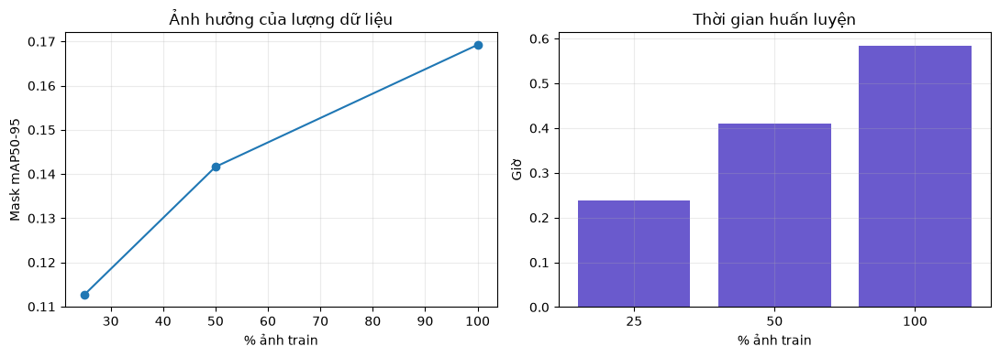

,Train images,Mask mAP50-95,Mask mAP50,Train hours
Train %,,,,
25,300,0.113,0.167,0.239
50,600,0.142,0.208,0.410
100,1200,0.169,0.258,0.585


In [19]:
study_checkpoints = {25: study_ckpt_25, 50: study_ckpt_50, 100: checkpoints['YOLO26n']}
study_times = {25: study_time_25, 50: study_time_50, 100: train_seconds['YOLO26n']}
study_rows = []
for percent, checkpoint in study_checkpoints.items():
    metrics = YOLO(str(checkpoint), task='segment').val(
        data=str(yaml_path), split='val', imgsz=IMG_SIZE, batch=1,
        device=DEVICE, rect=False, plots=False, verbose=False)
    study_rows.append({'Train %': percent, 'Train images': len(train_files) * percent // 100,
                       'Mask mAP50-95': float(metrics.seg.map),
                       'Mask mAP50': float(metrics.seg.map50),
                       'Train hours': study_times[percent] / 3600})
study_df = pd.DataFrame(study_rows).set_index('Train %').sort_index()
study_df.to_csv(REPORT_ROOT / 'data_fraction_study.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(study_df.index, study_df['Mask mAP50-95'], marker='o')
axes[0].set(xlabel='% ảnh train', ylabel='Mask mAP50-95', title='Ảnh hưởng của lượng dữ liệu')
axes[1].bar(study_df.index.astype(str), study_df['Train hours'], color='slateblue')
axes[1].set(xlabel='% ảnh train', ylabel='Giờ', title='Thời gian huấn luyện')
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(REPORT_ROOT / 'data_fraction_study.png', dpi=150); plt.show()
display(study_df.round(3))


## 7. Mở rộng triển khai: ONNX FP32 trên CPU

ONNX được so với chính checkpoint PyTorch đã export, trước hết bằng Mask mAP trên validation, sau đó bằng độ trễ dự đoán từng ảnh. Benchmark dùng cùng ảnh, cùng ngưỡng và process riêng cho từng biến thể. Tốc độ là đặc tính của phần cứng và runtime đang dùng.

In [20]:
onnx_paths = {}
if EXPORT_ONNX:
    import shutil
    for name, best in checkpoints.items():
        target = EXPORT_ROOT / f'{name.lower()}_taco10_fp32.onnx'
        exported = Path(YOLO(str(best)).export(format='onnx', imgsz=IMG_SIZE, batch=1,
                                               dynamic=False, simplify=True, nms=None, device='cpu'))
        if exported.resolve() != target.resolve(): shutil.copy2(exported, target)
        onnx.checker.check_model(str(target))
        onnx_paths[name] = target
        print(name, 'ONNX FP32:', round(target.stat().st_size / 1e6, 2), 'MB')
else:
    for name in MODEL_SPECS:
        target = EXPORT_ROOT / f'{name.lower()}_taco10_fp32.onnx'
        assert target.is_file(), f'Không thấy {target}'
        onnx_paths[name] = target


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CPU (AMD Ryzen 9 9950X 16-Core Processor)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs



PyTorch: starting from '/workspace/workspace/lt/taco10_study/runs/yolo26n_taco10-8/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 46, 8400), (1, 32, 160, 160)) (6.3 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.98...


...


ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success ✅ 0.6s, saved as '/workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7/weights/best.onnx' (39.9 MB)



Export complete (0.7s)
Results saved to /workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7/weights/best.onnx
Predict:         yolo predict task=segment model=/workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7/weights/best.onnx imgsz=640 
Validate:        yolo val task=segment model=/workspace/workspace/lt/taco10_study/runs/yolo26s_taco10-7/weights/best.onnx imgsz=640 data=/workspace/workspace/lt/taco10_study/yolo/data.yaml 
Visualize:       https://netron.app


YOLO26s ONNX FP32: 41.79 MB


In [21]:
onnx_val_rows, onnx_val_per_class = {}, {}
for name, path in onnx_paths.items():
    key = f'{name} ONNX FP32'
    onnx_val_rows[key], onnx_val_per_class[key] = eval_seg(path, 'val', 'cpu')

val_all = pd.concat([val_table, pd.DataFrame(onnx_val_rows).T])
order = [f'{name} {backend}' for name in MODEL_SPECS for backend in ('PyTorch', 'ONNX FP32')]
val_all = val_all.reindex(order)

val_all.to_csv(REPORT_ROOT / 'validation_all.csv')
display(val_all.round(4))

for name in MODEL_SPECS:
    diff = val_all.loc[f'{name} ONNX FP32', 'Mask mAP50-95'] - val_all.loc[f'{name} PyTorch', 'Mask mAP50-95']
    print(f'{name}: ONNX - PyTorch Mask mAP50-95 = {diff:+.5f} ({diff*100:+.3f} pp)')
    if abs(diff) > .02:
        print('WARNING: Difference exceeds 2 percentage points.')


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CPU (AMD Ryzen 9 9950X 16-Core Processor)


Loading /workspace/workspace/lt/taco10_study/exports/yolo26n_taco10_fp32.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.31.1 with CPUExecutionProvider


Setting batch=1 input of shape (1, 3, 640, 640)


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 14113.6±5364.0 MB/s, size: 1453.0 KB)


...

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11785.9±1828.9 MB/s, size: 1357.2 KB)


                   all        150        526      0.387      0.304      0.294      0.221      0.382      0.292       0.28      0.194


Speed: 0.2ms preprocess, 66.6ms inference, 0.0ms loss, 22.0ms postprocess per image


,Box mAP50,Box mAP50-95,Mask mAP50,Mask mAP50-95
YOLO26n PyTorch,0.2730,0.1981,0.2582,0.1692
YOLO26n ONNX FP32,0.2730,0.1981,0.2583,0.1692
YOLO26s PyTorch,0.2941,0.2205,0.2799,0.1940
YOLO26s ONNX FP32,0.2939,0.2207,0.2798,0.1936


YOLO26n: ONNX - PyTorch Mask mAP50-95 = -0.00004 (-0.004 pp)
YOLO26s: ONNX - PyTorch Mask mAP50-95 = -0.00045 (-0.045 pp)


In [22]:
import subprocess, sys

bench_paths = sorted(p for p in (YOLO_ROOT / 'images/val').iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})[:BENCHMARK_IMAGES]
assert len(bench_paths) == BENCHMARK_IMAGES
specs = [(label, path) for name in MODEL_SPECS for label, path in
         ((f'{name} PyTorch', checkpoints[name]), (f'{name} ONNX FP32', onnx_paths[name]))]
worker = '''
import cv2, json, sys, time
from ultralytics import YOLO
cfg = json.loads(sys.argv[1])
images = [cv2.imread(p) for p in cfg['images']]
assert all(im is not None for im in images)
model = YOLO(cfg['model'], task='segment')
args = dict(device='cpu', imgsz=cfg['imgsz'], conf=.25, rect=False, verbose=False)
for image in images[:cfg['warmup']]: model.predict(image, **args)
rows = []
for repeat in range(cfg['repeats']):
    for image_idx, image in enumerate(images):
        start = time.perf_counter()
        model.predict(image, **args)
        rows.append(dict(repeat=repeat, image_idx=image_idx,
                         latency_ms=1000 * (time.perf_counter() - start)))
print('BENCH_RESULT=' + json.dumps(rows))
'''
raw_rows = []
for label, checkpoint in specs:
    payload = dict(model=str(checkpoint), images=[str(p) for p in bench_paths],
                   imgsz=IMG_SIZE, warmup=min(BENCHMARK_WARMUP, len(bench_paths)),
                   repeats=BENCHMARK_REPEATS)
    result = subprocess.run([sys.executable, '-c', worker, json.dumps(payload)],
                            capture_output=True, text=True)
    if result.returncode: raise RuntimeError(f'{label}: {result.stderr[-3000:]}')
    line = next((x for x in result.stdout.splitlines() if x.startswith('BENCH_RESULT=')), None)
    if line is None: raise RuntimeError(f'{label}: {result.stdout[-1000:]}')
    raw_rows.extend({'Variant': label, **row} for row in json.loads(line.removeprefix('BENCH_RESULT=')))
    print(label, 'done')
lat_raw = pd.DataFrame(raw_rows)
lat_raw.to_csv(REPORT_ROOT / 'cpu_latency_raw.csv', index=False)
lat_summary = lat_raw.groupby('Variant')['latency_ms'].agg(
    count='size', mean_ms='mean', std_ms='std', median_ms='median',
    p95_ms=lambda x: x.quantile(.95)).reindex([label for label, _ in specs])
lat_summary['FPS_sequential_est'] = 1000 / lat_summary['mean_ms']
lat_summary.to_csv(REPORT_ROOT / 'cpu_latency_summary.csv')
display(lat_summary.round(2))


YOLO26n PyTorch done


YOLO26n ONNX FP32 done


YOLO26s PyTorch done


YOLO26s ONNX FP32 done


,count,mean_ms,std_ms,median_ms,p95_ms,FPS_sequential_est
Variant,,,,,,
YOLO26n PyTorch,250,13.78,0.61,13.82,14.64,72.59
YOLO26n ONNX FP32,250,34.58,14.52,34.79,59.04,28.92
YOLO26s PyTorch,250,29.15,1.08,29.13,30.12,34.30
YOLO26s ONNX FP32,250,71.55,23.42,76.79,107.39,13.98


## 8. Test cuối và kết luận

Sau khi đã chọn cấu hình trên validation, đánh giá hai checkpoint chính trên test. Phần mở rộng 25/50/100% và ONNX không dùng test để điều chỉnh tham số.

In [23]:
test_rows = {}
if RUN_FINAL_TEST:
    for name, checkpoint in checkpoints.items():
        metrics = YOLO(str(checkpoint), task='segment').val(
            data=str(yaml_path), split='test', imgsz=IMG_SIZE, batch=1,
            device=DEVICE, rect=False, plots=False, verbose=False)
        test_rows[name] = {'Box mAP50-95': float(metrics.box.map),
                           'Mask mAP50': float(metrics.seg.map50),
                           'Mask mAP50-95': float(metrics.seg.map)}
    test_df = pd.DataFrame.from_dict(test_rows, orient='index')
    test_df.to_csv(REPORT_ROOT / 'test_metrics.csv')
    display(test_df.round(4))
else:
    print('Test chưa chạy. Bật RUN_FINAL_TEST khi đã chốt cấu hình trên validation.')


Ultralytics 8.4.194 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)


YOLO26n-seg summary (fused): 137 layers, 2,705,970 parameters, 0 gradients, 9.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1393.2±209.1 MB/s, size: 1954.2 KB)


val: New cache created: /workspace/workspace/lt/taco10_study/yolo/labels/test.cache


                   all        150        503       0.29      0.382      0.271      0.188      0.281      0.372      0.265      0.173


...

YOLO26s-seg summary (fused): 136 layers, 10,369,210 parameters, 0 gradients, 34.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 15627.4±3556.9 MB/s, size: 2154.7 KB)


                   all        150        503      0.437      0.324      0.322      0.233      0.346      0.369      0.313      0.212


Speed: 3.4ms preprocess, 5.8ms inference, 0.0ms loss, 7.1ms postprocess per image


,Box mAP50-95,Mask mAP50,Mask mAP50-95
YOLO26n,0.1881,0.2653,0.1727
YOLO26s,0.2335,0.3127,0.2120


In [24]:
summary = val_table.loc[[f'{name} PyTorch' for name in MODEL_SPECS],
                        ['Mask mAP50', 'Mask mAP50-95']].copy()
summary.index = list(MODEL_SPECS)
summary['Train hours'] = pd.Series({name: seconds / 3600 for name, seconds in train_seconds.items()})
summary['Checkpoint MB'] = pd.Series({name: p.stat().st_size / 1e6 for name, p in checkpoints.items()})
if RUN_FINAL_TEST: summary['Test Mask mAP50-95'] = test_df['Mask mAP50-95']
summary.to_csv(REPORT_ROOT / 'final_model_summary.csv')
display(summary.round(3))
if RUN_FINAL_TEST:
    winner = test_df['Mask mAP50-95'].idxmax()
    print(f'Test Mask mAP50-95 cao nhất: {winner} = {test_df.loc[winner, "Mask mAP50-95"]:.3f}')
print(f'Dữ liệu 25% → 100%: Mask mAP50-95 {study_df.loc[25, "Mask mAP50-95"]:.3f} → {study_df.loc[100, "Mask mAP50-95"]:.3f}')
for name in MODEL_SPECS:
    pt = lat_summary.loc[f'{name} PyTorch', 'mean_ms']
    ox = lat_summary.loc[f'{name} ONNX FP32', 'mean_ms']
    print(f'{name}: PyTorch {pt:.1f} ms/ảnh, ONNX FP32 {ox:.1f} ms/ảnh trên CPU local')
print('Biểu đồ/CSV đã lưu trong:', REPORT_ROOT)


,Mask mAP50,Mask mAP50-95,Train hours,Checkpoint MB,Test Mask mAP50-95
YOLO26n,0.258,0.169,0.585,6.593,0.173
YOLO26s,0.280,0.194,0.404,23.326,0.212


Test Mask mAP50-95 cao nhất: YOLO26s = 0.212
Dữ liệu 25% → 100%: Mask mAP50-95 0.113 → 0.169
YOLO26n: PyTorch 13.8 ms/ảnh, ONNX FP32 34.6 ms/ảnh trên CPU local
YOLO26s: PyTorch 29.2 ms/ảnh, ONNX FP32 71.5 ms/ảnh trên CPU local
Biểu đồ/CSV đã lưu trong: /workspace/workspace/lt/taco10_study/reports


### Nhận xét cần trình bày sau khi chạy

- Nêu mô hình có Mask mAP50-95 tốt hơn và mức chênh lệch so với thời gian huấn luyện, dung lượng.
- Đối chiếu biểu đồ 25/50/100% với phân bố lớp và các ảnh có nhiều FN/FP.
- Báo cáo ONNX theo số đo trên máy đang dùng, kể cả khi chậm hơn PyTorch CPU. FPS trong bảng là ước tính cho suy luận tuần tự, batch 1, không tính đọc ảnh hay tải mô hình.
- Một split và một seed chưa đủ để suy rộng kết quả; các lớp hiếm có AP biến động lớn.